<a href="https://colab.research.google.com/github/SalmiFatimaZahra/Gestion-des-salaires-des-employ-s-dans-une-entreprise-/blob/main/ENSIAS_Transformers_TextMining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformers appliqués au Text Mining — Projet ENSIAS
**Data & Software Sciences · Présentation scientifique + expérimentation**

Ce notebook **fusionne** la démonstration des mécanismes internes du Transformer et le pipeline de traduction **anglais → français** à partir d'**OPUS Books**, avec **fine-tuning de MarianMT (3 époques)**.

### Plan expérimental
| Partie | Contenu | Résultat attendu |
|---|---|---|
| A | Embeddings, positions, Q/K/V, self-attention et masque causal | Matrices et heatmaps pédagogiques |
| B | Corpus OPUS Books, nettoyage, splits, analyse exploratoire et TF-IDF | Statistiques Text Mining |
| C | MarianMT préentraîné : prédictions initiales | BLEU/chrF de départ |
| D | Fine-tuning supervisé (3 époques) | Training Loss, Validation Loss |
| E | Réévaluation sur le même test | Comparaison avant/après, erreurs |
| F | Encoder / Decoder / Cross-Attention | Visualisations d'un modèle appris |

**Précautions scientifiques :** (1) les vecteurs de la partie A sont fictifs ou aléatoires ; (2) le modèle MarianMT est déjà préentraîné ; (3) le corpus OPUS Books peut présenter un chevauchement avec des données préalables du modèle, donc les scores ne prouvent pas une généralisation indépendante ; (4) n'inventez pas les métriques si la partie en ligne n'a pas été exécutée.

> **Exécution** : Google Colab, **GPU T4 conseillé** (Exécution → Modifier le type d'exécution → GPU). Une connexion est nécessaire au premier chargement du corpus et du modèle. Le notebook fonctionne également en **mode hors ligne** pour toute la partie A.

## 0. Environnement et paramètres
- `RUN_ONLINE` : téléchargement et analyse du corpus + modèle Hugging Face.
- `RUN_FINETUNING` : vrai entraînement de MarianMT (3 époques). Nécessite de préférence un GPU ; sur CPU désactivé par défaut.
- `TRAIN_N`, `VAL_N`, `TEST_N` : sous-ensembles distincts **après déduplication des sources**.
- Relancer le notebook depuis le début si ces variables sont modifiées.

In [ ]:
import os, sys, random, time, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

RUN_ONLINE = os.environ.get("ENSIAS_OFFLINE_TEST", "0") != "1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUN_FINETUNING = RUN_ONLINE and DEVICE.type == "cuda"  # mettre True pour forcer le CPU (plus lent)
TRAIN_N, VAL_N, TEST_N = 1000, 200, 200
N_EPOCHS, LR = 3, 2e-5
BATCH = 8 if DEVICE.type == "cuda" else 2
MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH = 64, 64
DATASET_NAME, DATASET_CONFIG = "Helsinki-NLP/opus_books", "en-fr"
MODEL_NAME = "Helsinki-NLP/opus-mt-en-fr"
OUTPUT_DIR = "./marianmt-en-fr-textmining-ensias"
EVAL_N = 80  # même échantillon de test avant/après
plt.rcParams.update({"figure.figsize": (8,4), "figure.dpi": 110, "font.size": 10})
print("Python :", sys.version.split()[0], "| Torch :", torch.__version__, "| Matériel :", DEVICE)
print("Mode en ligne :", RUN_ONLINE, "| Fine-tuning :", RUN_FINETUNING)
print("Époques :", N_EPOCHS, "| Splits ciblés :", (TRAIN_N, VAL_N, TEST_N))

Python : 3.13.16 | Torch : 2.11.0+cu130 | Matériel : cuda
Mode en ligne : True | Fine-tuning : True
Époques : 3 | Splits ciblés : (1000, 200, 200)


In [ ]:
# Installation conditionnelle des dépendances en ligne.
# Les opérations NumPy/PyTorch suivantes fonctionnent même sans accès Internet.
if RUN_ONLINE:
    required = ["datasets", "transformers", "accelerate", "sentencepiece", "sacrebleu", "sklearn"]
    absent = [name for name in required if importlib.util.find_spec(name) is None]
    if absent:
        import subprocess
        print("Installation des bibliothèques manquantes :", absent)
        packages = ["transformers>=4.50,<5", "datasets>=3,<6", "accelerate>=1.4,<2", "sentencepiece>=0.2", "sacrebleu>=2", "scikit-learn>=1.4"]
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
        except Exception as err:
            print("⚠ Impossible d'installer les dépendances Hugging Face :", str(err)[:300])
            RUN_ONLINE = False
            RUN_FINETUNING = False
else:
    print("Mode hors ligne : aucun téléchargement nécessaire.")

Installation des bibliothèques manquantes : ['sacrebleu']


---
# PARTIE A —  le Transformer (mathématiques et visualisations)
Les prochaines cellules proviennent du notebook de démonstration ENSIAS initial. Elles n'entraînent aucun réseau et peuvent être exécutées sans Internet.

---
## 1. De la phrase aux vecteurs : tokens et embeddings

Un Transformer ne manipule pas directement des mots : il reçoit une matrice `X ∈ ℝⁿˣᵈ`, où `n` est le nombre de tokens et `d` la dimension des représentations.

Dans le **Transformer original**, on additionne un embedding de token et une information positionnelle :

\[
X_i = E_i + PE(i)
\]

L'exemple suivant utilise une **tokenisation simplifiée par mots** pour rendre la démonstration intuitive. Les modèles réels utilisent souvent une tokenisation en sous-mots (ex. SentencePiece).

In [ ]:
phrase = "Sara gave the report because she was ready"
tokens = phrase.split()
d_model = 8
rng = np.random.default_rng(SEED)
E = rng.normal(0, 0.3, size=(len(tokens), d_model))

print("Tokens :", tokens)
print("Matrice des embeddings E :", E.shape)
print(pd.DataFrame(np.round(E[:4], 3), index=tokens[:4],
                   columns=[f"e{i}" for i in range(d_model)]))

Tokens : ['Sara', 'gave', 'the', 'report', 'because', 'she', 'was', 'ready']
Matrice des embeddings E : (8, 8)
           e0     e1     e2     e3     e4     e5     e6     e7
Sara    0.091 -0.312  0.225  0.282 -0.585 -0.391  0.038 -0.095
gave   -0.005 -0.256  0.264  0.233  0.020  0.338  0.140 -0.258
the     0.111 -0.288  0.264 -0.015 -0.055 -0.204  0.367 -0.046
report -0.128 -0.106  0.160  0.110  0.124  0.129  0.642 -0.122


### Encodage positionnel sinusoïdal (Vaswani et al., 2017)

Pour les indices pairs `2i` et impairs `2i+1` :

\[
PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d}}\right),\quad
PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d}}\right)
\]

Les dimensions évoluent à différentes fréquences, ce qui ajoute une information de position à l'embedding.

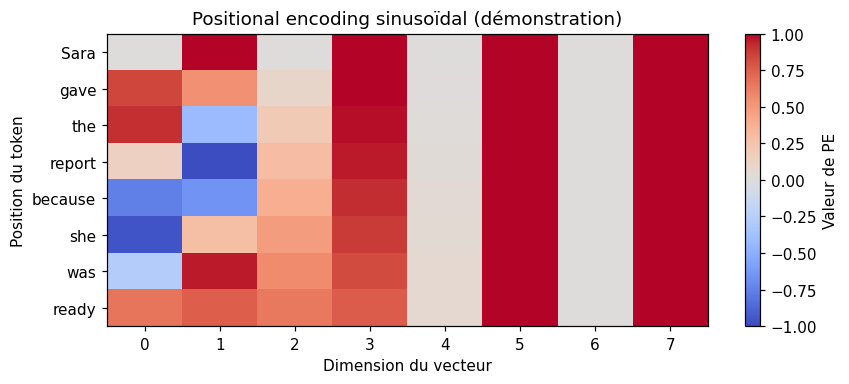

Forme de X = E + PE : (8, 8)


In [ ]:
def positional_encoding(n_positions: int, d: int) -> np.ndarray:
    if d % 2:
        raise ValueError("Utiliser une dimension paire pour cette démonstration.")
    pos = np.arange(n_positions)[:, None]
    i = np.arange(0, d, 2)
    frequencies = np.exp(-np.log(10000.0) * i / d)
    angles = pos * frequencies[None, :]
    pe = np.zeros((n_positions, d), dtype=float)
    pe[:, 0::2] = np.sin(angles)
    pe[:, 1::2] = np.cos(angles)
    return pe

PE = positional_encoding(len(tokens), d_model)
X = E + PE
assert X.shape == (len(tokens), d_model)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(PE, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
ax.set(xlabel="Dimension du vecteur", ylabel="Position du token",
       title="Positional encoding sinusoïdal (démonstration)")
ax.set_yticks(np.arange(len(tokens)), labels=tokens)
ax.set_xticks(np.arange(d_model))
fig.colorbar(im, ax=ax, label="Valeur de PE"); plt.tight_layout(); plt.show()
print("Forme de X = E + PE :", X.shape)

---
## 2. Q, K, V : un calcul numérique *à la main*

Nous reprenons l'exemple scientifique de la PPT pour la requête du mot **« elle »**. Pour trois candidats (`Sara`, `rapport`, `prête`), nous fixons des vecteurs artificiels de taille `dₖ = 3`.

\[
s_j = \frac{q \cdot k_j}{\sqrt{d_k}},\qquad
\alpha_j = \operatorname{softmax}(s)_j,\qquad
z = \sum_j \alpha_j v_j.
\]

**À l'oral :** `Query = ce que je cherche`, `Key = comment je peux être sélectionné`, `Value = l'information que je fournis`.

In [ ]:
labels = ["Sara", "rapport", "prête"]
q = np.array([0.95, 0.75, 0.10])
K = np.array([
    [0.90, 0.80, 0.10],   # Sara
    [0.10, 0.20, 0.90],   # rapport
    [0.50, 0.40, 0.20],   # prête
])
V = np.array([
    [0.30, 0.90, 0.20, 0.80],
    [0.70, 0.10, 0.80, 0.20],
    [0.20, 0.60, 0.30, 0.90],
])

def softmax_numpy(a, axis=-1):
    shifted = a - np.max(a, axis=axis, keepdims=True)
    e = np.exp(shifted)
    return e / e.sum(axis=axis, keepdims=True)

scores_bruts = K @ q
scores = scores_bruts / np.sqrt(K.shape[1])
weights = softmax_numpy(scores)
z = weights @ V

result = pd.DataFrame({
    "Token": labels,
    "Score brut q·k": np.round(scores_bruts, 3),
    "Score / √3": np.round(scores, 3),
    "Poids softmax (%)": np.round(100 * weights, 2),
})
display(result)
print("Somme des poids :", round(weights.sum(), 6))
print("Vecteur contextualisé z :", np.round(z, 3))
assert np.isclose(weights.sum(), 1.0)
assert np.allclose(weights, [0.454545, 0.236723, 0.308732], atol=1e-4)
assert np.allclose(z, [0.363816, 0.618002, 0.372907, 0.688839], atol=1e-4)

,Token,Score brut q·k,Score / √3,Poids softmax (%)
0,Sara,1.465,0.846,45.45
1,rapport,0.335,0.193,23.67
2,prête,0.795,0.459,30.87


Somme des poids : 1.0
Vecteur contextualisé z : [0.364 0.618 0.373 0.689]


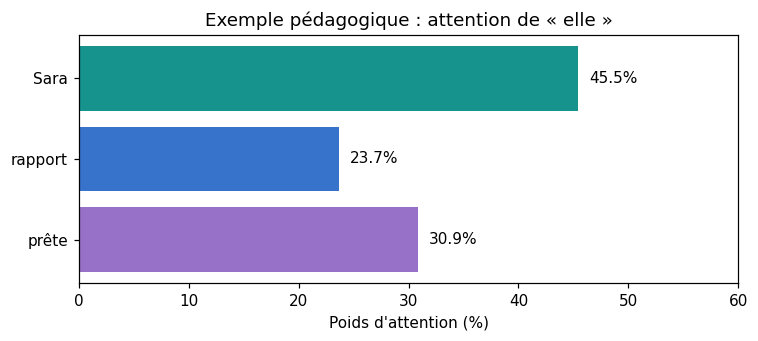

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(labels, weights * 100, color=["#16938c", "#3772cb", "#9770c7"])
ax.invert_yaxis(); ax.set_xlim(0, 60)
ax.set_xlabel("Poids d'attention (%)")
ax.set_title("Exemple pédagogique : attention de « elle »")
for bar, w in zip(bars, weights):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f"{100*w:.1f}%", va="center", fontsize=10)
plt.tight_layout(); plt.show()

**Interprétation :** `Sara` reçoit environ 45,5 % du poids dans **cette construction fictive**. Cela permet d'expliquer la combinaison pondérée des Values, mais **ne prouve pas qu'un vrai modèle apprend automatiquement la coréférence**.

---
## 3. Calcul matriciel de la Self-Attention

Pour une séquence de `n` tokens :

\[
Q=XW_Q,\quad K=XW_K,\quad V=XW_V,
\qquad \operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V.
\]

Les matrices `W_Q`, `W_K` et `W_V` sont normalement **apprises**. Nous allons ici les initialiser aléatoirement pour comprendre les dimensions et les opérations. Comme ce n'est pas entraîné, les poids d'attention **n'ont pas d'interprétation sémantique garantie**.

In [ ]:
n, d = X.shape
d_k, d_v = 4, 5
W_Q = rng.normal(0, 0.2, (d, d_k))
W_K = rng.normal(0, 0.2, (d, d_k))
W_V = rng.normal(0, 0.2, (d, d_v))
Q, Kmat, Vmat = X @ W_Q, X @ W_K, X @ W_V
S = (Q @ Kmat.T) / np.sqrt(d_k)
A = softmax_numpy(S, axis=-1)
Z = A @ Vmat

print(f"X : {X.shape}  |  Q : {Q.shape}  |  K : {Kmat.shape}  |  V : {Vmat.shape}")
print(f"Scores : {S.shape}  |  Attention : {A.shape}  |  Sortie : {Z.shape}")
assert A.shape == (n, n) and Z.shape == (n, d_v)
assert np.allclose(A.sum(axis=1), np.ones(n))

X : (8, 8)  |  Q : (8, 4)  |  K : (8, 4)  |  V : (8, 5)
Scores : (8, 8)  |  Attention : (8, 8)  |  Sortie : (8, 5)


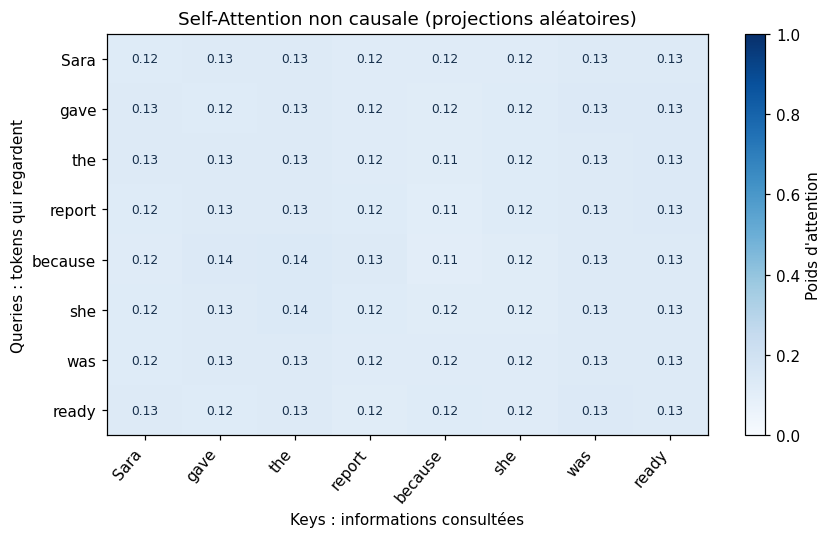

In [ ]:
def show_attention(matrix, row_labels, col_labels=None, title="Matrice d'attention", figsize=(8, 5)):
    M = np.asarray(matrix)
    if col_labels is None:
        col_labels = row_labels
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(np.arange(len(col_labels)), labels=col_labels, rotation=50, ha="right")
    ax.set_yticks(np.arange(len(row_labels)), labels=row_labels)
    ax.set_xlabel("Keys : informations consultées")
    ax.set_ylabel("Queries : tokens qui regardent")
    ax.set_title(title)
    if M.size <= 90:
        for (i, j), value in np.ndenumerate(M):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    color="white" if value > 0.65 else "#17304c", fontsize=8)
    fig.colorbar(im, ax=ax, label="Poids d'attention")
    plt.tight_layout(); plt.show()

show_attention(A, tokens, title="Self-Attention non causale (projections aléatoires)")

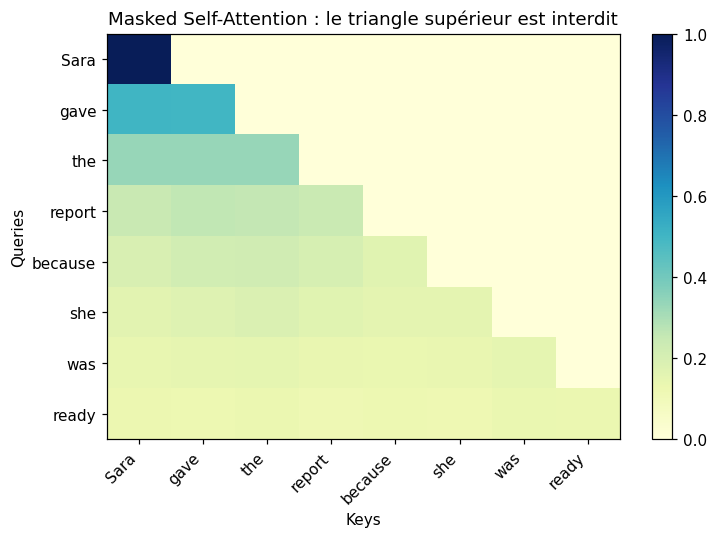

Poids maximal au-dessus de la diagonale : 0.0


In [ ]:
N = len(tokens)
allowed = np.tril(np.ones((N, N), dtype=bool))
S_masked = np.where(allowed, S, -np.inf)
A_masked = softmax_numpy(S_masked, axis=-1)
assert np.all(A_masked[~allowed] == 0)
assert np.allclose(A_masked.sum(axis=1), 1.0)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(A_masked, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(np.arange(N), labels=tokens, rotation=45, ha="right")
ax.set_yticks(np.arange(N), labels=tokens)
ax.set_title("Masked Self-Attention : le triangle supérieur est interdit")
ax.set(xlabel="Keys", ylabel="Queries")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
print("Poids maximal au-dessus de la diagonale :", A_masked[~allowed].max())

---
## 5. Multi-Head Attention avec PyTorch

La Multi-Head Attention calcule plusieurs attentions avec des projections distinctes, concatène leurs sorties puis applique une projection finale.

\[
\operatorname{MultiHead}(Q,K,V) = \operatorname{Concat}(head_1,\dots,head_h)W^O
\]

Nous utiliserons `torch.nn.MultiheadAttention` avec deux têtes. La couche n'étant pas entraînée, il faut observer **la structure et les dimensions**, pas chercher à interpréter la langue.

PyTorch : 2.11.0+cu130
Entrée  : (1, 8, 8)
Sortie  : (1, 8, 8)
Attention par tête (batch, heads, n, n) : (1, 2, 8, 8)


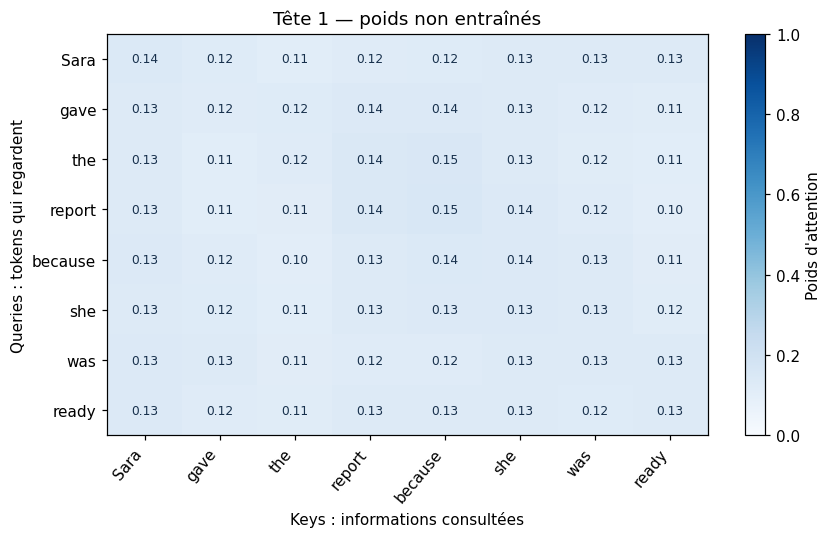

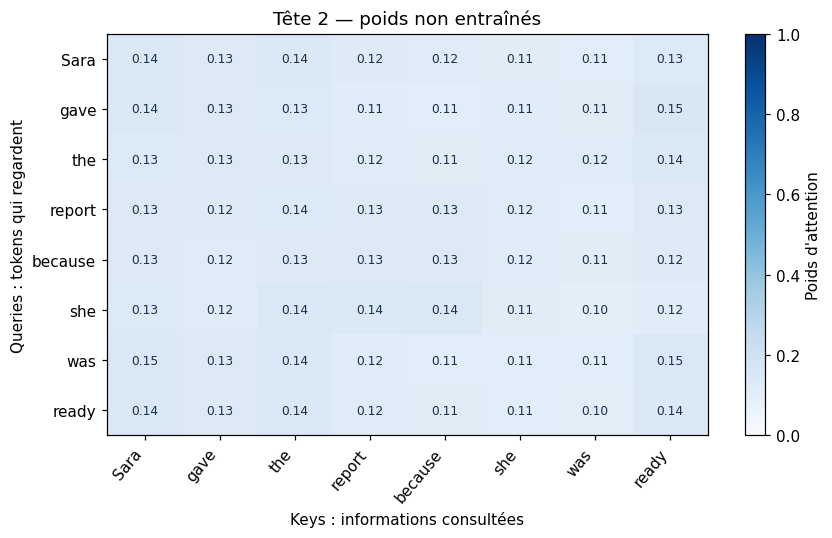

In [ ]:
import torch
from torch import nn

torch.manual_seed(SEED)
print("PyTorch :", torch.__version__)

# Entrée attendue : (batch, séquence, d_model)
x_t = torch.tensor(X, dtype=torch.float32).unsqueeze(0)
module = nn.MultiheadAttention(embed_dim=d_model, num_heads=2, batch_first=True)
module.eval()
with torch.no_grad():
    out, heads = module(x_t, x_t, x_t, need_weights=True,
                        average_attn_weights=False)

print("Entrée  :", tuple(x_t.shape))
print("Sortie  :", tuple(out.shape))
print("Attention par tête (batch, heads, n, n) :", tuple(heads.shape))
assert tuple(heads.shape) == (1, 2, len(tokens), len(tokens))
show_attention(heads[0, 0].numpy(), tokens, title="Tête 1 — poids non entraînés")
show_attention(heads[0, 1].numpy(), tokens, title="Tête 2 — poids non entraînés")

Test de masquage causal : OK (tous les poids futurs valent 0).


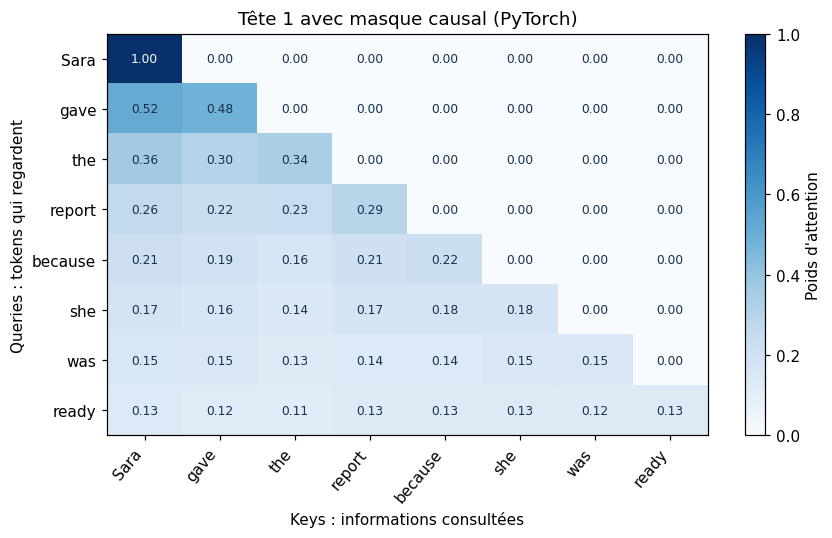

In [ ]:
# Vérifier qu'un masque causal empêche réellement l'accès aux positions futures.
causal_torch = torch.triu(torch.ones(N, N, dtype=torch.bool), diagonal=1)
with torch.no_grad():
    out_causal, heads_causal = module(
        x_t, x_t, x_t, attn_mask=causal_torch,
        need_weights=True, average_attn_weights=False
    )

future_values = heads_causal[0, :, causal_torch]
assert torch.all(future_values == 0)
print("Test de masquage causal : OK (tous les poids futurs valent 0).")
show_attention(heads_causal[0, 0].numpy(), tokens,
               title="Tête 1 avec masque causal (PyTorch)")

---
# PARTIE B — Text Mining du corpus OPUS Books
**Objectif** : disposer de couples de phrases alignées anglais–français, explorer le corpus et préparer des splits reproductibles.

1. Extraire les deux langues, normaliser les espaces et éliminer les paires vides.
2. Supprimer les doublons selon le **texte source anglais** avant séparation (pour éviter la même entrée exacte dans plusieurs splits).
3. Séparer aléatoirement les exemples en `train`, `validation`, `test`, **sans tester sur le train**.
4. Analyser les longueurs et les mots discriminants par TF-IDF.

⚠️ L'élimination des doublons exacts ne garantit pas une séparation par livre ou auteur ni l'absence de recouvrement avec le préentraînement de MarianMT.

In [ ]:
import re
from collections import Counter
hf_ready = False
data = None
raw = None

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.replace("\u00a0", " ")
    return re.sub(r"\s+", " ", text).strip()

if RUN_ONLINE:
    try:
        from datasets import load_dataset, Dataset, DatasetDict
        raw = load_dataset(DATASET_NAME, DATASET_CONFIG, split="train")
        # On commence par un sous-échantillon aléatoire plus large, puis on nettoie.
        candidate_n = min(len(raw), 25000)
        candidate = raw.shuffle(seed=SEED).select(range(candidate_n))
        records = []
        for item in candidate:
            pair = item.get("translation", {})
            if not isinstance(pair, dict):
                continue
            en = clean_text(pair.get("en", ""))
            fr = clean_text(pair.get("fr", ""))
            if en and fr and 5 <= len(en) <= 300 and 5 <= len(fr) <= 300:
                records.append({"source":en, "target":fr})
        frame = pd.DataFrame(records).drop_duplicates(subset=["source"]).reset_index(drop=True)
        needed = TRAIN_N + VAL_N + TEST_N
        if len(frame) < needed:
            raise ValueError(f"Seulement {len(frame)} paires valides après nettoyage ; besoin de {needed}. Augmentez candidate_n.")
        frame = frame.sample(frac=1, random_state=SEED).reset_index(drop=True)
        train_df = frame.iloc[:TRAIN_N].copy()
        val_df = frame.iloc[TRAIN_N:TRAIN_N + VAL_N].copy()
        test_df = frame.iloc[TRAIN_N + VAL_N:needed].copy()
        data = DatasetDict({
            "train":Dataset.from_pandas(train_df, preserve_index=False),
            "validation":Dataset.from_pandas(val_df, preserve_index=False),
            "test":Dataset.from_pandas(test_df, preserve_index=False)
        })
        s = {k:set(data[k]["source"]) for k in data}
        assert not (s["train"] & s["validation"] or s["train"] & s["test"] or s["validation"] & s["test"])
        hf_ready = True
        print("Paires du corpus chargées :", len(raw), "| après nettoyage :", len(frame))
        print("Splits définitifs :", {k:len(v) for k,v in data.items()})
        display(pd.DataFrame(data["train"][:3]))
    except Exception as exc:
        print("⚠ Corpus inaccessible :", repr(exc)[:500])
        hf_ready = False
else:
    print("Corpus non chargé en mode hors ligne. Aucune mesure réelle ne sera inventée.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

en-fr/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Paires du corpus chargées : 127085 | après nettoyage : 23358
Splits définitifs : {'train': 1000, 'validation': 200, 'test': 200}


,source,target
0,Emma was radiant at this news.,Emma s’épanouit à cette nouvelle.
1,"""Fifty pistoles at most.""",-- Cinquante pistoles tout au plus.
2,"""Bah!"" he exclaimed, ""Therese will cure that.","—Bah! reprit-il, Thérèse guérira cela…."


,Split,Paires,Moyenne mots anglais,Moyenne mots français
0,train,1000,18.7,18.3
1,validation,200,17.3,17.2
2,test,200,19.5,18.7


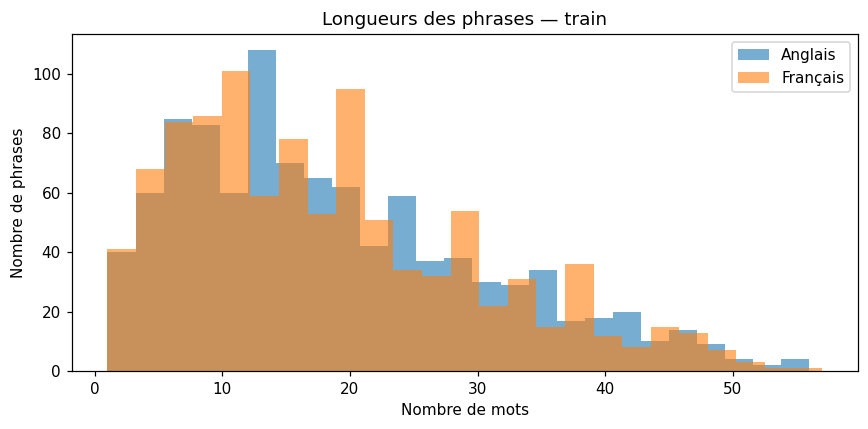

In [ ]:
if hf_ready:
    stats=[]
    for split in ["train","validation","test"]:
        ex = data[split]
        lengths_en = [len(t.split()) for t in ex["source"]]
        lengths_fr = [len(t.split()) for t in ex["target"]]
        stats.append({"Split":split,"Paires":len(ex),"Moyenne mots anglais":round(np.mean(lengths_en),1),"Moyenne mots français":round(np.mean(lengths_fr),1)})
    display(pd.DataFrame(stats))
    en_lens=[len(x.split()) for x in data["train"]["source"]]
    fr_lens=[len(x.split()) for x in data["train"]["target"]]
    fig, ax = plt.subplots(figsize=(8,4))
    ax.hist(en_lens, bins=25, alpha=.6, label="Anglais")
    ax.hist(fr_lens, bins=25, alpha=.6, label="Français")
    ax.set(xlabel="Nombre de mots", ylabel="Nombre de phrases", title="Longueurs des phrases — train")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Exploration non exécutée : corpus non chargé.")

### TF-IDF : une représentation classique de Text Mining
À la différence des embeddings contextualisés, **TF-IDF** quantifie l'importance statistique d'un terme dans un document/ensemble de documents. C'est une analyse exploratoire du corpus, **pas un composant de MarianMT**.

Matrice TF-IDF : (1000, 1500)


,terme,importance_TF_IDF
0,said,0.021464
1,la,0.009530
2,say,0.008840
3,il,0.008837
4,did,0.008655
5,good,0.008447
6,know,0.008211
7,tell,0.007871
8,great,0.007724
9,le,0.007699


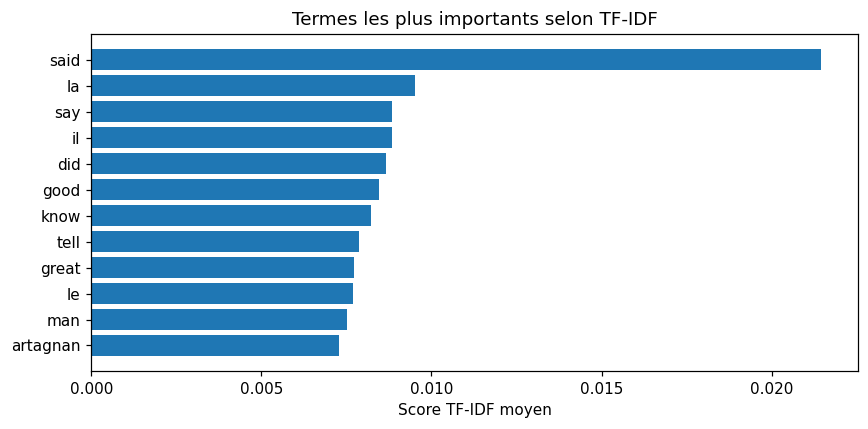

In [ ]:
if hf_ready:
    from sklearn.feature_extraction.text import TfidfVectorizer
    tfidf = TfidfVectorizer(max_features=1500, stop_words="english", ngram_range=(1,2))
    tfidf_matrix = tfidf.fit_transform(data["train"]["source"])
    means = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
    top = np.argsort(means)[-12:][::-1]
    tops = pd.DataFrame({"terme":tfidf.get_feature_names_out()[top], "importance_TF_IDF":means[top]})
    print("Matrice TF-IDF :", tfidf_matrix.shape)
    display(tops)
    fig, ax=plt.subplots(figsize=(8,4))
    ax.barh(tops["terme"][::-1], tops["importance_TF_IDF"][::-1])
    ax.set(title="Termes les plus importants selon TF-IDF",xlabel="Score TF-IDF moyen")
    plt.tight_layout(); plt.show()
else:
    print("TF-IDF disponible après chargement du corpus.")

---
# PARTIE C — MarianMT préentraîné : modèle de référence avant fine-tuning
**MarianMT** est un Transformer Encoder–Decoder. Le tokenizer construit les sous-mots ; le modèle charge ses poids déjà appris.

Nous mesurons la traduction sur **les mêmes `EVAL_N` phrases de test** avant et après fine-tuning. BLEU et chrF sont des scores entre 0 et 100. Cette comparaison est indicative sur un petit échantillon ; elle n'est pas un benchmark indépendant. <small>Modèle : `Helsinki-NLP/opus-mt-en-fr`.</small>

In [ ]:
model = None; tokenizer = None; tokenized = None; trainer = None
baseline_scores = None; tuned_scores = None
baseline_predictions = None; tuned_predictions = None
subset_test = None

if hf_ready:
    try:
        from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM,
                                  DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments)
        import sacrebleu
        tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
        # eager permet généralement l'inspection des poids d'attention avec MarianMT
        try:
            model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, attn_implementation="eager")
        except (TypeError, ValueError):
            model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
        model.to(DEVICE)
        model.eval()
        subset_test = data["test"].select(range(min(EVAL_N,len(data["test"]))))
        print("Modèle chargé :", MODEL_NAME)
        print("Évaluation sur", len(subset_test), "phrases test distinctes du train.")
    except Exception as exc:
        print("⚠ Impossible de charger MarianMT :", repr(exc)[:500])
        model = None
else:
    print("Chargement du modèle ignoré (mode hors ligne ou corpus indisponible).")

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


pytorch_model.bin:   0%|          | 0.00/301M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

Modèle chargé : Helsinki-NLP/opus-mt-en-fr
Évaluation sur 80 phrases test distinctes du train.


In [ ]:
def generate_translations(net, texts, batch_size=8):
    """Traduction batchée, en conservant l'ordre des exemples."""
    if net is None or tokenizer is None:
        raise RuntimeError("Modèle/tokenizer non chargé")
    net.eval()
    results=[]
    start=time.perf_counter()
    with torch.inference_mode():
        for i in range(0,len(texts),batch_size):
            chunk = list(texts[i:i+batch_size])
            inp = tokenizer(chunk, return_tensors="pt", padding=True,
                            truncation=True, max_length=MAX_SOURCE_LENGTH).to(DEVICE)
            generated = net.generate(**inp,num_beams=3,max_new_tokens=MAX_TARGET_LENGTH)
            results += tokenizer.batch_decode(generated, skip_special_tokens=True)
    return results, time.perf_counter()-start

def translation_metrics(predictions, references):
    from sacrebleu import corpus_bleu, corpus_chrf
    return {
        "BLEU":round(corpus_bleu(predictions,[list(references)]).score,2),
        "chrF":round(corpus_chrf(predictions,[list(references)]).score,2)
    }

if model is not None:
    refs = subset_test["target"]
    baseline_predictions, baseline_seconds = generate_translations(model, subset_test["source"], batch_size=BATCH)
    baseline_scores=translation_metrics(baseline_predictions, refs)
    print("Mesures AVANT fine-tuning :", baseline_scores)
    print("Temps de génération (s) :", round(baseline_seconds,1))
    display(pd.DataFrame({"Anglais":subset_test["source"][:5],
                          "Référence française":refs[:5],
                          "MarianMT avant fine-tuning":baseline_predictions[:5]}))
else:
    print("Prédictions initiales non exécutées.")

Mesures AVANT fine-tuning : {'BLEU': 21.35, 'chrF': 50.28}
Temps de génération (s) : 13.7


,Anglais,Référence française,MarianMT avant fine-tuning
0,I naturally abhorred dirt and rags; I had been...,J'avais une horreur naturelle de la saleté et ...,J'ai naturellement abhorré la saleté et les ch...
1,Old Rouault was seeing him off; they were walk...,Le père Rouault lui fit la conduite; ils march...,Le vieux Rouault le voyait partir; ils marchai...
2,I had to obey.,Il fallut obéir.,J'ai dû obéir.
3,"""Medicine!"" said the archdeacon, tossing his h...",– Médecine ! » dit l’archidiacre en hochant la...,"– Médicine ! dit l'archidiacre, en lui jetant ..."
4,"""And why pillage me?""",Et pourquoi me piller?,"""Et pourquoi me piller ?"""


---
# PARTIE D — Fine-tuning supervisé (3 époques)
Un exemple d'entraînement comprend une phrase anglaise d'entrée et sa traduction française attendue. À chaque étape :

1. **Encoder** : représentations contextualisées de l'anglais.
2. **Decoder** : prédiction des tokens français sous masque causal.
3. **Loss** : entropie croisée entre tokens prédits et attendus (*teacher forcing*).
4. **Backpropagation** : calcul des gradients ; l'optimiseur met à jour les poids.
5. **Validation** après chaque époque : calcul de la `eval_loss` sur des paires non vues pendant le fine-tuning.

**Données prévues :** 1 000 train, 200 validation, 200 test ; **3 époques** ; LR `2e-5` ; batch 8 sur GPU. La configuration est modifiable en tête du notebook. Avec CPU, `RUN_FINETUNING=False` par défaut pour éviter une attente très longue.

In [ ]:
if model is not None:
    def preprocess(batch):
        inputs = tokenizer(batch["source"], max_length=MAX_SOURCE_LENGTH, truncation=True)
        targets = tokenizer(text_target=batch["target"], max_length=MAX_TARGET_LENGTH, truncation=True)
        inputs["labels"] = targets["input_ids"]
        return inputs

    tokenized=data.map(preprocess,batched=True,remove_columns=data["train"].column_names)
    collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, label_pad_token_id=-100)
    sample=tokenized["train"][0]
    print("Exemple tokenisé :", {k:len(v) for k,v in sample.items()})
    print("Paires par split :", {split:len(ds) for split,ds in tokenized.items()})
else:
    print("Tokenisation supervisée non exécutée.")

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Exemple tokenisé : {'input_ids': 8, 'attention_mask': 8, 'labels': 11}
Paires par split : {'train': 1000, 'validation': 200, 'test': 200}


In [ ]:
# Construire d'abord les arguments PUIS le Trainer, et n'appeler train() qu'une fois.
# Aucun résultat fictif n'est ajouté à history.
if model is not None and RUN_FINETUNING:
    import inspect
    args = Seq2SeqTrainingArguments(
        output_dir=OUTPUT_DIR,
        num_train_epochs=N_EPOCHS,
        learning_rate=LR,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=BATCH,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=2,
        logging_strategy="steps",
        logging_steps=25,
        weight_decay=0.01,
        warmup_ratio=0.05,
        fp16=(DEVICE.type == "cuda"),
        predict_with_generate=False,  # validation loss, pas génération coûteuse à chaque époque
        report_to="none",
        seed=SEED
    )
    kwargs=dict(model=model, args=args, train_dataset=tokenized["train"],
                eval_dataset=tokenized["validation"], data_collator=collator)
    if "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters:
        kwargs["processing_class"] = tokenizer
    else:
        kwargs["tokenizer"] = tokenizer
    trainer = Seq2SeqTrainer(**kwargs)
    print("Trainer prêt :", len(tokenized["train"]), "train |", N_EPOCHS, "époques")
else:
    print("Trainer non construit. Conditions : charger OPUS/MarianMT et activer RUN_FINETUNING (GPU recommandé).")

Trainer prêt : 1000 train | 3 époques


In [ ]:
train_result = None
if trainer is not None:
    t0 = time.perf_counter()
    train_result = trainer.train()
    training_seconds=time.perf_counter()-t0
    model=trainer.model
    print("FIN DU FINE-TUNING —", N_EPOCHS, "époques prévues")
    print("Temps réel d'entraînement (minutes) :", round(training_seconds/60,2))
    print("Métriques d'entraînement :", train_result.metrics)
else:
    print("Fine-tuning non lancé : aucune époque exécutée.")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss
1,1.978300,1.988046
2,1.877100,1.950450
3,1.729500,1.941450


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 4, 'bad_words_ids': [[59513]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(
There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.encoder.embed_positions.weight', 'model.decoder.embed_tokens.weight', 'model.decoder.embed_positions.weight', 'lm_head.weight'].


FIN DU FINE-TUNING — 3 époques prévues
Temps réel d'entraînement (minutes) : 1.36
Métriques d'entraînement : {'train_runtime': 81.1415, 'train_samples_per_second': 36.972, 'train_steps_per_second': 4.622, 'total_flos': 42216176222208.0, 'train_loss': 1.9332080891927084, 'epoch': 3.0}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
7,1.8911,5.672117,1.129213e-05,1.4,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1.8995,5.294418,9.887640e-06,1.6,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1.7698,5.519602,8.483146e-06,1.8,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,1.8771,5.177391,7.078652e-06,2.0,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,NaN,NaN,NaN,2.0,250,1.95045,0.6145,325.487,40.686,NaN,NaN,NaN,NaN,NaN
12,1.7535,5.323384,5.674157e-06,2.2,275,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,1.7714,7.564310,4.269663e-06,2.4,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,1.7675,7.273590,2.865169e-06,2.6,325,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,1.6339,5.224895,1.460674e-06,2.8,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,1.7295,6.450670,5.617978e-08,3.0,375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


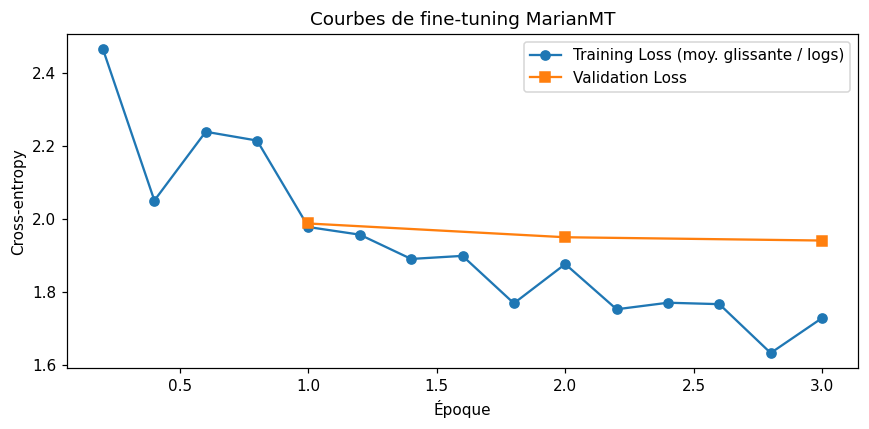

Meilleure Validation Loss observée : 1.9414


In [ ]:
history_df=pd.DataFrame()
if trainer is not None and train_result is not None:
    history_df=pd.DataFrame(trainer.state.log_history)
    display(history_df.tail(12))
    fig,ax=plt.subplots(figsize=(8,4))
    tr=history_df.dropna(subset=["loss"]) if "loss" in history_df else pd.DataFrame()
    va=history_df.dropna(subset=["eval_loss"]) if "eval_loss" in history_df else pd.DataFrame()
    if not tr.empty: ax.plot(tr["epoch"],tr["loss"],marker="o",label="Training Loss (moy. glissante / logs)")
    if not va.empty: ax.plot(va["epoch"],va["eval_loss"],marker="s",label="Validation Loss")
    ax.set(xlabel="Époque",ylabel="Cross-entropy",title="Courbes de fine-tuning MarianMT")
    ax.legend(); plt.tight_layout(); plt.show()
    if not va.empty:
        print("Meilleure Validation Loss observée :", round(va["eval_loss"].min(),4))
else:
    print("Aucune courbe d'entraînement : pas de fine-tuning effectué ici.")

---
# PARTIE E — Évaluer : BLEU, chrF et comparaison avant/après
Nous réévaluons le **meilleur checkpoint (sélection par la validation loss)** sur exactement les mêmes exemples de test qu'avant le fine-tuning. Un score supérieur ne suffit pas à affirmer une supériorité générale sur d'autres corpus.

,Modèle,BLEU,chrF
0,MarianMT préentraîné,21.35,50.28
1,MarianMT fine-tuné (3 époques),25.75,52.28


,Anglais,Référence,Avant,Après
0,I naturally abhorred dirt and rags; I had been...,J'avais une horreur naturelle de la saleté et ...,J'ai naturellement abhorré la saleté et les ch...,J'ai naturellement abhorré la saleté et les ch...
1,Old Rouault was seeing him off; they were walk...,Le père Rouault lui fit la conduite; ils march...,Le vieux Rouault le voyait partir; ils marchai...,"Le vieux Rouault le voyait partir, ils marchai..."
2,I had to obey.,Il fallut obéir.,J'ai dû obéir.,Il fallait que j'obéisse.
3,"""Medicine!"" said the archdeacon, tossing his h...",– Médecine ! » dit l’archidiacre en hochant la...,"– Médicine ! dit l'archidiacre, en lui jetant ...",«Médecin!» dit l'archidiacre en lui jetant la ...
4,"""And why pillage me?""",Et pourquoi me piller?,"""Et pourquoi me piller ?""",-- Et pourquoi me piller?
5,The crater of Snæfell resembled an inverted co...,Le cratère du Sneffels représentait un cône re...,Le cratère de Snæfell ressemblait à un cône in...,Le cratère de Snæfell ressemblait à un cône in...
6,"""Independent! What do you mean, Jane?""","-- Indépendante! que voulez-vous dire, Jane?","-- Indépendante! Qu'est-ce que tu veux dire, J...","-- Indépendante! que voulez-vous dire, Jane?"
7,"As for me, having some money in my pocket, I t...","Pour moi, ayant quelque argent dans ma poche, ...","Quant à moi, ayant de l'argent dans ma poche, ...","Quant à moi, ayant de l'argent dans ma poche, ..."
8,"Little by little, the cold being piercing, he ...","Peu à peu, le froid le pénétrant, il s’envelop...","Peu à peu, le froid étant perçant, il envelopp...","Peu à peu, le froid étant perçant, il envelopp..."
9,"""Captain Nemo, to my every objection you give ...","-- Capitaine Nemo, à toutes mes objections vou...","""Capitaine Nemo, à toutes mes objections, vous...","-- Capitaine Nemo, à toutes mes objections, vo..."


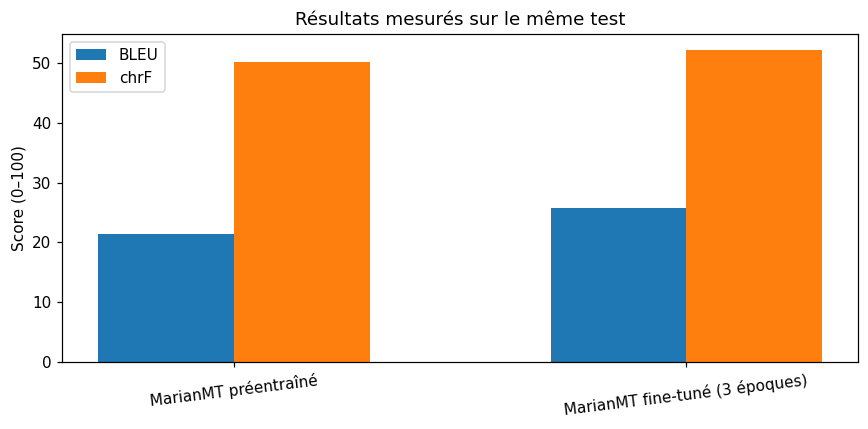

Durée de la seconde évaluation (s) : 6.8


In [ ]:
comparison_df = None; qualitative_df = None
if model is not None and train_result is not None and baseline_predictions is not None:
    tuned_predictions, tuned_seconds = generate_translations(model,subset_test["source"],batch_size=BATCH)
    tuned_scores=translation_metrics(tuned_predictions,subset_test["target"])
    comparison_df=pd.DataFrame([
        {"Modèle":"MarianMT préentraîné",**baseline_scores},
        {"Modèle":f"MarianMT fine-tuné ({N_EPOCHS} époques)",**tuned_scores}
    ])
    display(comparison_df)
    qualitative_df=pd.DataFrame({
        "Anglais":subset_test["source"],
        "Référence":subset_test["target"],
        "Avant":baseline_predictions,
        "Après":tuned_predictions
    })
    display(qualitative_df.head(12))
    fig,ax=plt.subplots(figsize=(8,4))
    p=np.arange(2); w=.3
    ax.bar(p-w/2,comparison_df["BLEU"],w,label="BLEU")
    ax.bar(p+w/2,comparison_df["chrF"],w,label="chrF")
    ax.set_xticks(p,comparison_df["Modèle"],rotation=7)
    ax.set(ylabel="Score (0–100)",title="Résultats mesurés sur le même test")
    ax.legend(); plt.tight_layout(); plt.show()
    qualitative_df.to_csv("predictions_avant_apres_ensias.csv", index=False)
    comparison_df.to_csv("scores_bleu_chrf_ensias.csv", index=False)
    print("Durée de la seconde évaluation (s) :",round(tuned_seconds,1))
else:
    print("Comparaison avant/après indisponible : le fine-tuning n'a pas été exécuté.")

In [ ]:
if qualitative_df is not None:
    # Détecter les exemples où les prédictions avant/après diffèrent.
    modified=qualitative_df[qualitative_df["Avant"] != qualitative_df["Après"]]
    print("Traductions modifiées :",len(modified),"/",len(qualitative_df))
    display(modified.head(10))
    # Il ne s'agit pas d'une mesure automatique de correction grammaticale.
    print("Lecture critique : vérifier manuellement les noms propres, omissions et choix lexicaux.")
else:
    print("Analyse qualitative disponible après fine-tuning.")

Traductions modifiées : 69 / 80


,Anglais,Référence,Avant,Après
0,I naturally abhorred dirt and rags; I had been...,J'avais une horreur naturelle de la saleté et ...,J'ai naturellement abhorré la saleté et les ch...,J'ai naturellement abhorré la saleté et les ch...
1,Old Rouault was seeing him off; they were walk...,Le père Rouault lui fit la conduite; ils march...,Le vieux Rouault le voyait partir; ils marchai...,"Le vieux Rouault le voyait partir, ils marchai..."
2,I had to obey.,Il fallut obéir.,J'ai dû obéir.,Il fallait que j'obéisse.
3,"""Medicine!"" said the archdeacon, tossing his h...",– Médecine ! » dit l’archidiacre en hochant la...,"– Médicine ! dit l'archidiacre, en lui jetant ...",«Médecin!» dit l'archidiacre en lui jetant la ...
4,"""And why pillage me?""",Et pourquoi me piller?,"""Et pourquoi me piller ?""",-- Et pourquoi me piller?
5,The crater of Snæfell resembled an inverted co...,Le cratère du Sneffels représentait un cône re...,Le cratère de Snæfell ressemblait à un cône in...,Le cratère de Snæfell ressemblait à un cône in...
6,"""Independent! What do you mean, Jane?""","-- Indépendante! que voulez-vous dire, Jane?","-- Indépendante! Qu'est-ce que tu veux dire, J...","-- Indépendante! que voulez-vous dire, Jane?"
7,"As for me, having some money in my pocket, I t...","Pour moi, ayant quelque argent dans ma poche, ...","Quant à moi, ayant de l'argent dans ma poche, ...","Quant à moi, ayant de l'argent dans ma poche, ..."
8,"Little by little, the cold being piercing, he ...","Peu à peu, le froid le pénétrant, il s’envelop...","Peu à peu, le froid étant perçant, il envelopp...","Peu à peu, le froid étant perçant, il envelopp..."
9,"""Captain Nemo, to my every objection you give ...","-- Capitaine Nemo, à toutes mes objections vou...","""Capitaine Nemo, à toutes mes objections, vous...","-- Capitaine Nemo, à toutes mes objections, vo..."


Lecture critique : vérifier manuellement les noms propres, omissions et choix lexicaux.


---
# PARTIE F — Attentions réelles de l'Encoder et du Decoder
On inspecte les poids du modèle préentraîné/fine-tuné avec **teacher forcing** sur une paire choisie. On distingue :
- **Self-Attention Encoder** (requêtes et clés anglaises),
- **Self-Attention Decoder** (attention causale côté français),
- **Cross-Attention** (queries du Decoder et keys/values de l'Encoder).

Ces heatmaps n'expliquent pas à elles seules pourquoi le modèle choisit une traduction. Selon les versions ou backends d'attention, certaines matrices peuvent être indisponibles : le notebook signale alors cette limite sans fabriquer de graphique.

Encoder self-attention (6, 6)


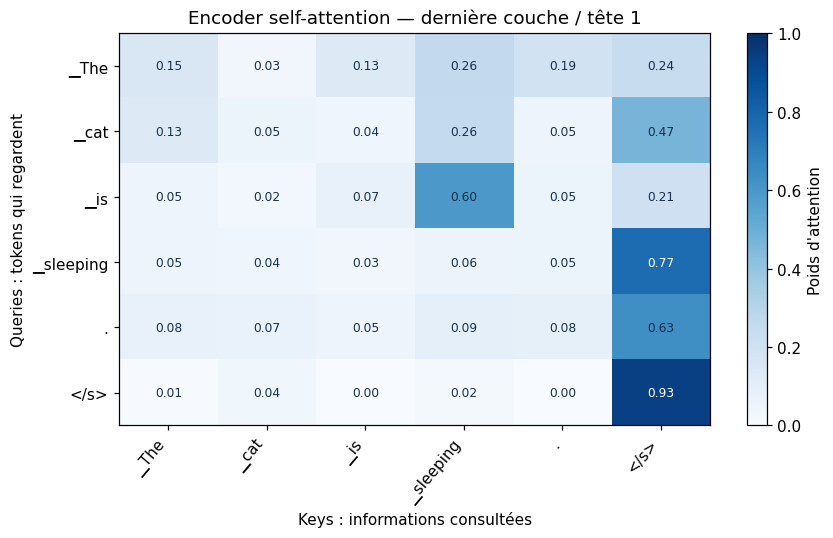

Decoder self-attention (7, 7)


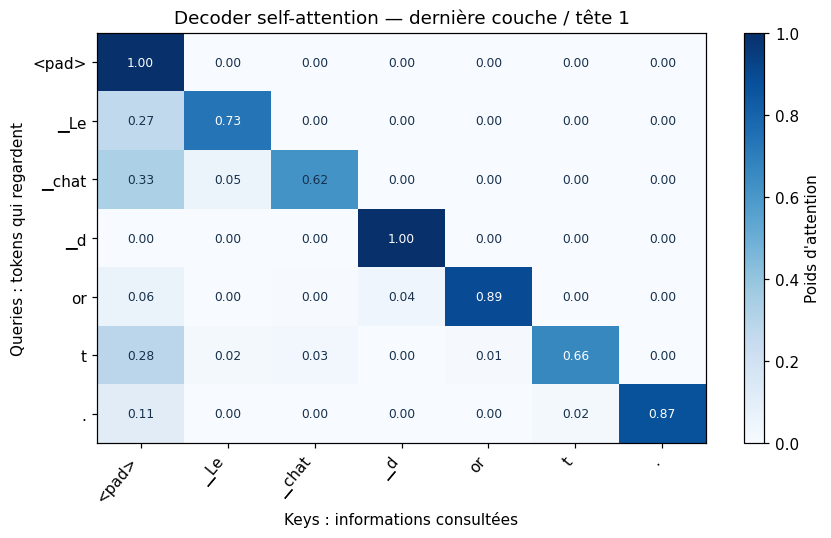

Cross-attention (7, 6)


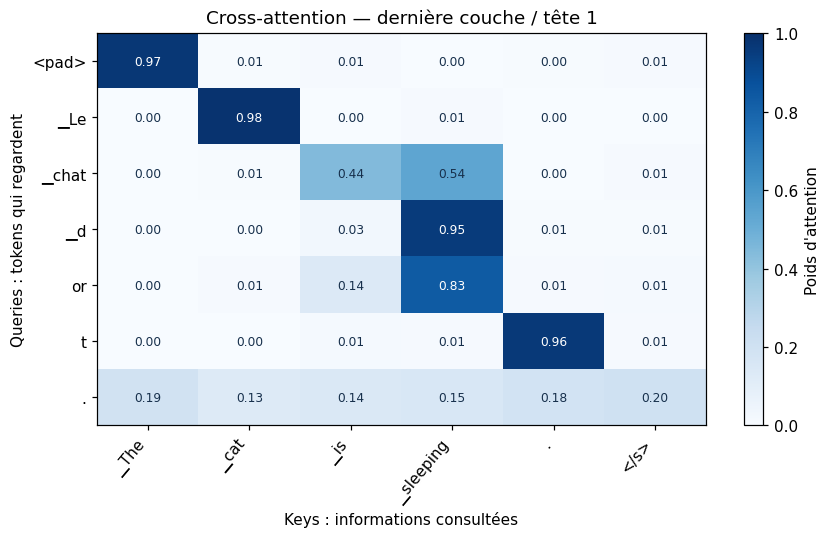

In [ ]:
if model is not None and tokenizer is not None:
    source = "The cat is sleeping."
    target = "Le chat dort."
    try:
        inp=tokenizer(source,return_tensors="pt").to(DEVICE)
        lbl=tokenizer(text_target=target,return_tensors="pt")["input_ids"].to(DEVICE)
        dec_ids=model.prepare_decoder_input_ids_from_labels(labels=lbl)
        model.eval()
        with torch.no_grad():
            att_out=model(**inp,decoder_input_ids=dec_ids,output_attentions=True,return_dict=True)
        source_labels=tokenizer.convert_ids_to_tokens(inp["input_ids"][0].tolist())
        decoder_labels=tokenizer.convert_ids_to_tokens(dec_ids[0].tolist())
        att_sets=[
            ("Encoder self-attention",getattr(att_out,"encoder_attentions",None),source_labels,source_labels),
            ("Decoder self-attention",getattr(att_out,"decoder_attentions",None),decoder_labels,decoder_labels),
            ("Cross-attention",getattr(att_out,"cross_attentions",None),decoder_labels,source_labels),
        ]
        for name,seq,row_labels,col_labels in att_sets:
            if seq and seq[-1] is not None:
                mat=seq[-1][0,0].detach().cpu().numpy()
                print(name,mat.shape)
                if mat.shape == (len(row_labels),len(col_labels)):
                    show_attention(mat,row_labels,col_labels,title=name+" — dernière couche / tête 1")
                else:
                    print("Tailles d'étiquettes et de matrice incompatibles, affichage ignoré.")
            else:
                print("Attention non exposée :",name)
    except Exception as exc:
        print("⚠ Inspection des poids impossible avec ce backend :",repr(exc)[:500])
else:
    print("Heatmaps apprises non disponibles hors ligne.")

---
# PARTIE G — Conclusion et préparation de l'oral

**Ce que montre scientifiquement ce notebook :**
1. L'attention est une combinaison pondérée de Values obtenue avec `softmax(QKᵀ / √dₖ)` ; on peut la calculer intégralement avec NumPy.
2. L'information positionnelle et le masque causal permettent d'utiliser l'attention dans des tâches séquentielles.
3. OPUS Books fournit les paires EN–FR nécessaires au fine-tuning supervisé ; l'analyse Text Mining (longueurs et TF-IDF) caractérise ces données.
4. MarianMT est un modèle **déjà préentraîné**, que l'on adapte pendant **3 époques si `RUN_FINETUNING=True`**. Les pertes et métriques doivent être effectivement générées, puis interprétées.
5. L'évaluation est indicative : sous-ensemble réduit, corpus littéraire, risques de chevauchement avec le préentraînement et absence de comparaison contrôlée avec RNN/LSTM entraînés dans les mêmes conditions.

### Questions possibles en classe
- **Pourquoi l'exécution du premier notebook était-elle si rapide ?** Il n'effectuait pas de mise à jour de poids.
- **Combien d'époques ?** 3 dans la partie fine-tuning, sinon 0 si l'entraînement est désactivé.
- **Pourquoi TF-IDF ?** Pour caractériser le corpus, pas pour fournir les embeddings de MarianMT.
- **Pourquoi BLEU et chrF ?** Ce sont des évaluations quantitatives de correspondance avec les références, qui restent incomplètes.
- **Pourquoi pas entraîner un Transformer depuis zéro ?** Une adaptation d'un modèle préentraîné est plus économique et permet d'observer une courbe d'apprentissage sur un petit corpus.

**Références :**
- Vaswani et al. (2017), [Attention Is All You Need](https://arxiv.org/abs/1706.03762).
- [Helsinki-NLP/opus_books](https://huggingface.co/datasets/Helsinki-NLP/opus_books) et [Helsinki-NLP/opus-mt-en-fr](https://huggingface.co/Helsinki-NLP/opus-mt-en-fr).
- [Hugging Face — Translation (Seq2SeqTrainer)](https://huggingface.co/docs/transformers/tasks/translation).